# 08_04 — Temporal CNN: vBCM from the last 50 shots' features

`BCM_GUN` of a shot from the dataset features of **this shot and the 49 before it** (a virtual BCM: no BCM readings
as input). A 1-D convolutional network over time can pick up temporal structure that a single shot does not show:
oscillations of the machine (the "repetitive" regime), slow drifts of a feature's gain, a feature that leads or lags
the charge by a few shots.

**Comparable with 08 and 08_02:** the same usable rows and test shots as 08 (the last `TEST_FRAC` = 20 % of each
segment), one model per charge regime trained on all of its segments (as 08_01 / 08_02), early stopping on the last
10 % of each segment's training part.

**Models on the same test shots:**
- **segment mean:** the segment's training mean;
- **MLP, current shot:** the MLP of 08 on the 10 features of the shot alone;
- **temporal CNN, L = 1:** the network below with a window of only the current shot, i.e. the same architecture
  without any temporal context;
- **temporal CNN, L = 50:** the network on the last 50 shots.

The difference between the two CNN columns is what the temporal context adds.

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from sklearn.compose import TransformedTargetRegressor
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATASETS = REPO / "results" / "datasets"

# the three regimes of the clean data, as in 08_01, by segment number
REGIMES = {"low charge": [0, 2, 3, 4], "high, repetitive": [5], "high, non-repetitive": [1, 6, 7]}
REGIME_OF = {s: r for r, segs in REGIMES.items() for s in segs}
TEST_FRAC = 0.2    # as 08: the last 20 % of each segment's shots are the test set
VAL_FRAC = 0.1     # early stopping on the last 10 % of each segment's training part (as 08_01 / 08_02)

L = 50                          # window: the current shot and the 49 before it
WIDTH, KERNEL, DILATIONS = 32, 5, (1, 2, 4, 8)   # receptive field 1 + (KERNEL - 1) * sum(DILATIONS) = 61 shots
SEEDS = (0, 1, 2)               # predictions averaged over these initial weights
BATCH, EPOCHS, PATIENCE, LR, WD = 256, 60, 8, 1e-3, 1e-4

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
torch.set_num_threads(8)
print(f"device {DEVICE}" + (f" ({torch.cuda.get_device_name()})" if DEVICE == "cuda" else ""))

device cuda (NVIDIA GB200)


## Shots and split

As 08_02. Per segment: **usable** = `valid` with a beam on the camera (the rows of 08); **test** = the last
`TEST_FRAC` of the segment's shots; **val** = the last `VAL_FRAC` of the usable training shots; **train** = the rest.
Only usable rows are trained on and scored, but a window may contain any row of the segment (see below).

In [2]:
manifest = json.loads((DATASETS / "manifest.json").read_text())
FEATURES = manifest["features"]
CAMERA = [f for f in FEATURES if f.startswith(("BTV_", "SVD_"))]
GROUP = {f: "camera" if f in CAMERA else f for f in FEATURES}         # one missing flag per instrument
FLAGS = [f"{g} missing" for g in dict.fromkeys(GROUP.values())]

parts = []
for info in manifest["segments"]:
    d = np.load(DATASETS / info["file"])
    p = pd.DataFrame(d["X"], columns=d["features"])
    p["lab_laser_power"] *= 1e6                                       # J -> µJ, see 08
    p.loc[d["btv_frozen"], CAMERA] = np.nan                           # a repeated image says nothing new
    p["BCM_GUN"] = d["y"]
    p["seg"], p["pos"] = info["segment"], np.arange(len(p))
    p["test"] = p["pos"] >= int(len(p) * (1 - TEST_FRAC))
    p["usable"] = d["valid"] & p[FEATURES].notna().all(axis=1).to_numpy()
    k = (p["usable"] & ~p["test"]).cumsum()
    p["val"] = p["usable"] & ~p["test"] & (k > (1 - VAL_FRAC) * k.max())
    parts.append(p)
df = pd.concat(parts, ignore_index=True)
df["regime"] = df["seg"].map(REGIME_OF)
df["train"] = df["usable"] & ~df["test"] & ~df["val"]
df["scored"] = df["usable"] & df["test"]

df.groupby("seg").agg(regime=("regime", "first"), shots=("pos", "size"), train=("train", "sum"), val=("val", "sum"),
                      test=("scored", "sum"), BCM_mean_nC=("BCM_GUN", "mean")).round(3)

,regime,shots,train,val,test,BCM_mean_nC
seg,,,,,,
0,low charge,6027,3262,363,948,0.223
1,"high, non-repetitive",19400,11406,1268,3732,4.829
2,low charge,200,110,13,31,0.144
3,low charge,7100,3820,425,1125,0.122
4,low charge,4500,2727,304,746,0.101
5,"high, repetitive",20000,12136,1349,3927,5.460
6,"high, non-repetitive",4100,2273,253,611,5.506
7,"high, non-repetitive",2000,1277,142,359,10.096


## The network

**Input:** a window of the last `L` rows of the segment, newest last. Each step holds the 10 features, standardised
on the regime's training shots, plus one flag per instrument (camera, laser meter, PGLA, PKI15A) that is 1 where its
reading is missing (blank or repeated camera image, the segment's last row, a NaN reading); a missing value itself
is 0 (the training mean). Steps before the segment's first shot are all-missing: a window never reaches into the
previous segment.

**Temporal CNN:** four causal 1-D convolutions over time (`WIDTH` channels, kernel `KERNEL`, dilations
`DILATIONS`, ReLU). "Causal": the output at a shot only sees that shot and earlier ones. With the dilations the
receptive field is 61 shots, so the output at the current shot sees the whole window: short patterns in the first
layers, periods up to tens of shots in the last ones. A small head (32 ReLU units, linear output) reads the last
step's convolution output **together with the current shot's inputs**, so the current shot does not have to pass
through all layers.

**Training:** target standardised on the training shots; L1 loss (the MAE, as 08_01's networks); AdamW (`LR`,
weight decay `WD`), batches of `BATCH` windows; early stopping on the validation shots (`PATIENCE` epochs without
improvement, at most `EPOCHS`, best epoch kept); predictions averaged over `SEEDS`.

In [3]:
class TemporalCNN(torch.nn.Module):
    def __init__(self, c_in, width=WIDTH, kernel=KERNEL, dilations=DILATIONS):
        super().__init__()
        self.pads = [(kernel - 1) * d for d in dilations]
        self.convs = torch.nn.ModuleList(torch.nn.Conv1d(c_in if i == 0 else width, width, kernel, dilation=d)
                                         for i, d in enumerate(dilations))
        self.head = torch.nn.Sequential(torch.nn.Linear(width + c_in, 32), torch.nn.ReLU(), torch.nn.Linear(32, 1))

    def forward(self, x):                                             # (batch, L, channels), newest last
        h = x.transpose(1, 2)
        for conv, pad in zip(self.convs, self.pads):
            h = F.relu(conv(F.pad(h, (pad, 0))))                      # left padding only: causal
        return self.head(torch.cat([h[:, :, -1], x[:, -1]], dim=1)).squeeze(-1)


def regime_inputs(rows):
    # The regime's rows -> step table A (rows + 1 all-missing pad row, channels) on DEVICE, standardised on training
    tr = df.loc[rows, "train"].to_numpy()
    X = df.loc[rows, FEATURES]
    X = (X - X[tr].mean()) / X[tr].std()
    flags = pd.DataFrame({f"{g} missing": X[[f for f in FEATURES if GROUP[f] == g]].isna().any(axis=1)
                          for g in dict.fromkeys(GROUP.values())}).astype(float)
    steps = np.hstack([X.fillna(0).to_numpy(), flags.to_numpy()]).astype(np.float32)
    pad = np.r_[np.zeros(len(FEATURES)), np.ones(len(FLAGS))].astype(np.float32)
    return torch.from_numpy(np.vstack([steps, pad])).to(DEVICE)


def windows(rows, L):
    # rows x L indices into the step table: the shot and the L - 1 before it, the pad row before the segment start
    pos, lag = df.loc[rows, "pos"].to_numpy(), np.arange(L - 1, -1, -1)
    I = np.where(pos[:, None] >= lag, np.arange(len(rows))[:, None] - lag, len(rows))
    return torch.from_numpy(I).to(DEVICE)


def fit_one(A, I, Y, fit, val, seed):
    torch.manual_seed(seed)
    model = TemporalCNN(A.shape[1]).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WD)
    predict = lambda b: torch.cat([model(A[I[c]]) for c in b.split(8192)])
    best, state, wait = np.inf, None, 0
    for epoch in range(1, EPOCHS + 1):
        model.train()
        for b in fit[torch.randperm(len(fit), device=DEVICE)].split(BATCH):
            loss = (model(A[I[b]]) - Y[b]).abs().mean()
            opt.zero_grad()
            loss.backward()
            opt.step()
        model.eval()
        with torch.no_grad():
            v = (predict(val) - Y[val]).abs().mean().item()
        if v < best:
            best, wait, state = v, 0, {k: t.detach().clone() for k, t in model.state_dict().items()}
        else:
            wait += 1
            if wait >= PATIENCE:
                break
    model.load_state_dict(state)
    model.eval()
    with torch.no_grad():
        return predict(torch.arange(len(I), device=DEVICE)).cpu().numpy(), epoch, best


def temporal_cnn(rows, L):
    # The network on windows of L shots, trained on the regime's rows -> predicted BCM (nC) on those rows
    A, I = regime_inputs(rows), windows(rows, L)
    y = df.loc[rows, "BCM_GUN"].to_numpy(np.float32)
    tr = df.loc[rows, "train"].to_numpy()
    mu, sd = y[tr].mean(), y[tr].std()
    Y = torch.from_numpy((y - mu) / sd).to(DEVICE)
    fit, val = (torch.from_numpy(np.flatnonzero(df.loc[rows, k].to_numpy())).to(DEVICE) for k in ("train", "val"))
    runs = [fit_one(A, I, Y, fit, val, seed) for seed in SEEDS]
    print(f"  L={L}: epochs {[r[1] for r in runs]}, validation MAE {[round(r[2] * sd * 1000, 1) for r in runs]} pC")
    return pd.Series(np.mean([r[0] for r in runs], axis=0) * sd + mu, index=rows)


print(f"{sum(p.numel() for p in TemporalCNN(len(FEATURES) + len(FLAGS)).parameters())} weights, "
      f"{len(FEATURES) + len(FLAGS)} input channels ({len(FEATURES)} features + {len(FLAGS)} missing flags)")

19265 weights, 14 input channels (10 features + 4 missing flags)


## Training, one model per regime

The MLP of 08 on the current shot is the per-shot reference (trained on the training and validation shots: it
does its own early stopping).

In [4]:
def mlp():
    return TransformedTargetRegressor(
        regressor=make_pipeline(StandardScaler(),
                                MLPRegressor(hidden_layer_sizes=(32, 16), activation="relu", alpha=1e-3,
                                             learning_rate_init=1e-3, max_iter=2000, early_stopping=True,
                                             validation_fraction=0.2, n_iter_no_change=30, random_state=0)),
        transformer=StandardScaler())


preds = {}
for rname, segs in REGIMES.items():
    print(rname)
    rows = df.index[df["seg"].isin(segs)]
    trv = (df.loc[rows, "train"] | df.loc[rows, "val"]).to_numpy()
    use = rows[df.loc[rows, "usable"].to_numpy()]
    p = {"segment mean": df.loc[rows, "seg"].map(df[df["train"] | df["val"]].groupby("seg")["BCM_GUN"].mean())}
    m = mlp().fit(df.loc[rows[trv], FEATURES], df.loc[rows[trv], "BCM_GUN"])
    p["MLP, current shot"] = pd.Series(m.predict(df.loc[use, FEATURES]), index=use)
    p["temporal CNN, L=1"] = temporal_cnn(rows.to_numpy(), 1)
    p[f"temporal CNN, L={L}"] = temporal_cnn(rows.to_numpy(), L)
    preds[rname] = p
MODELS = list(next(iter(preds.values())))

low charge


  L=1: epochs [29, 26, 24], validation MAE [np.float32(10.2), np.float32(9.7), np.float32(10.0)] pC


  L=50: epochs [24, 38, 41], validation MAE [np.float32(9.8), np.float32(9.5), np.float32(9.7)] pC
high, repetitive


  L=1: epochs [37, 33, 28], validation MAE [np.float32(74.9), np.float32(75.1), np.float32(75.3)] pC


  L=50: epochs [22, 21, 20], validation MAE [np.float32(78.8), np.float32(78.4), np.float32(77.7)] pC
high, non-repetitive


  L=1: epochs [10, 31, 12], validation MAE [np.float32(157.8), np.float32(152.3), np.float32(164.4)] pC


  L=50: epochs [24, 27, 24], validation MAE [np.float32(98.8), np.float32(108.2), np.float32(91.9)] pC


## Results

Same layout and test shots as the tables of 08 and 08_02. Best per segment in bold. The last two columns differ
only in the window length: their difference is the temporal context.

In [5]:
rows, curves = [], {}
for rname, segs in REGIMES.items():
    for s in segs:
        i = df.index[df["scored"] & (df["seg"] == s)]
        y = df.loc[i, "BCM_GUN"]
        row = {("", "regime"): rname, ("", "train"): int((df["train"] | df["val"])[df["seg"] == s].sum()),
               ("", "test"): len(i), ("", "BCM mean (pC)"): 1000 * y.mean(), ("", "BCM std (pC)"): 1000 * y.std()}
        for name in MODELS:
            row[("MAE (pC)", name)] = 1000 * mean_absolute_error(y, preds[rname][name][i])
        for name in MODELS:
            row[("R2", name)] = r2_score(y, preds[rname][name][i])
        rows.append(pd.Series(row, name=s))
        curves[s] = (y.to_numpy(), {name: preds[rname][name][i].to_numpy() for name in MODELS})
summary = pd.DataFrame(rows).rename_axis("segment").sort_index()
summary.columns = pd.MultiIndex.from_tuples(summary.columns)

mae, r2 = [("MAE (pC)", m) for m in MODELS], [("R2", m) for m in MODELS]
(summary.style
    .format("{:.0f}", subset=[("", "train"), ("", "test"), ("", "BCM mean (pC)")])
    .format("{:.1f}", subset=[("", "BCM std (pC)")] + mae)
    .format("{:.3f}", subset=r2)
    .highlight_min(subset=mae, axis=1, props="font-weight: bold")
    .highlight_max(subset=r2, axis=1, props="font-weight: bold"))

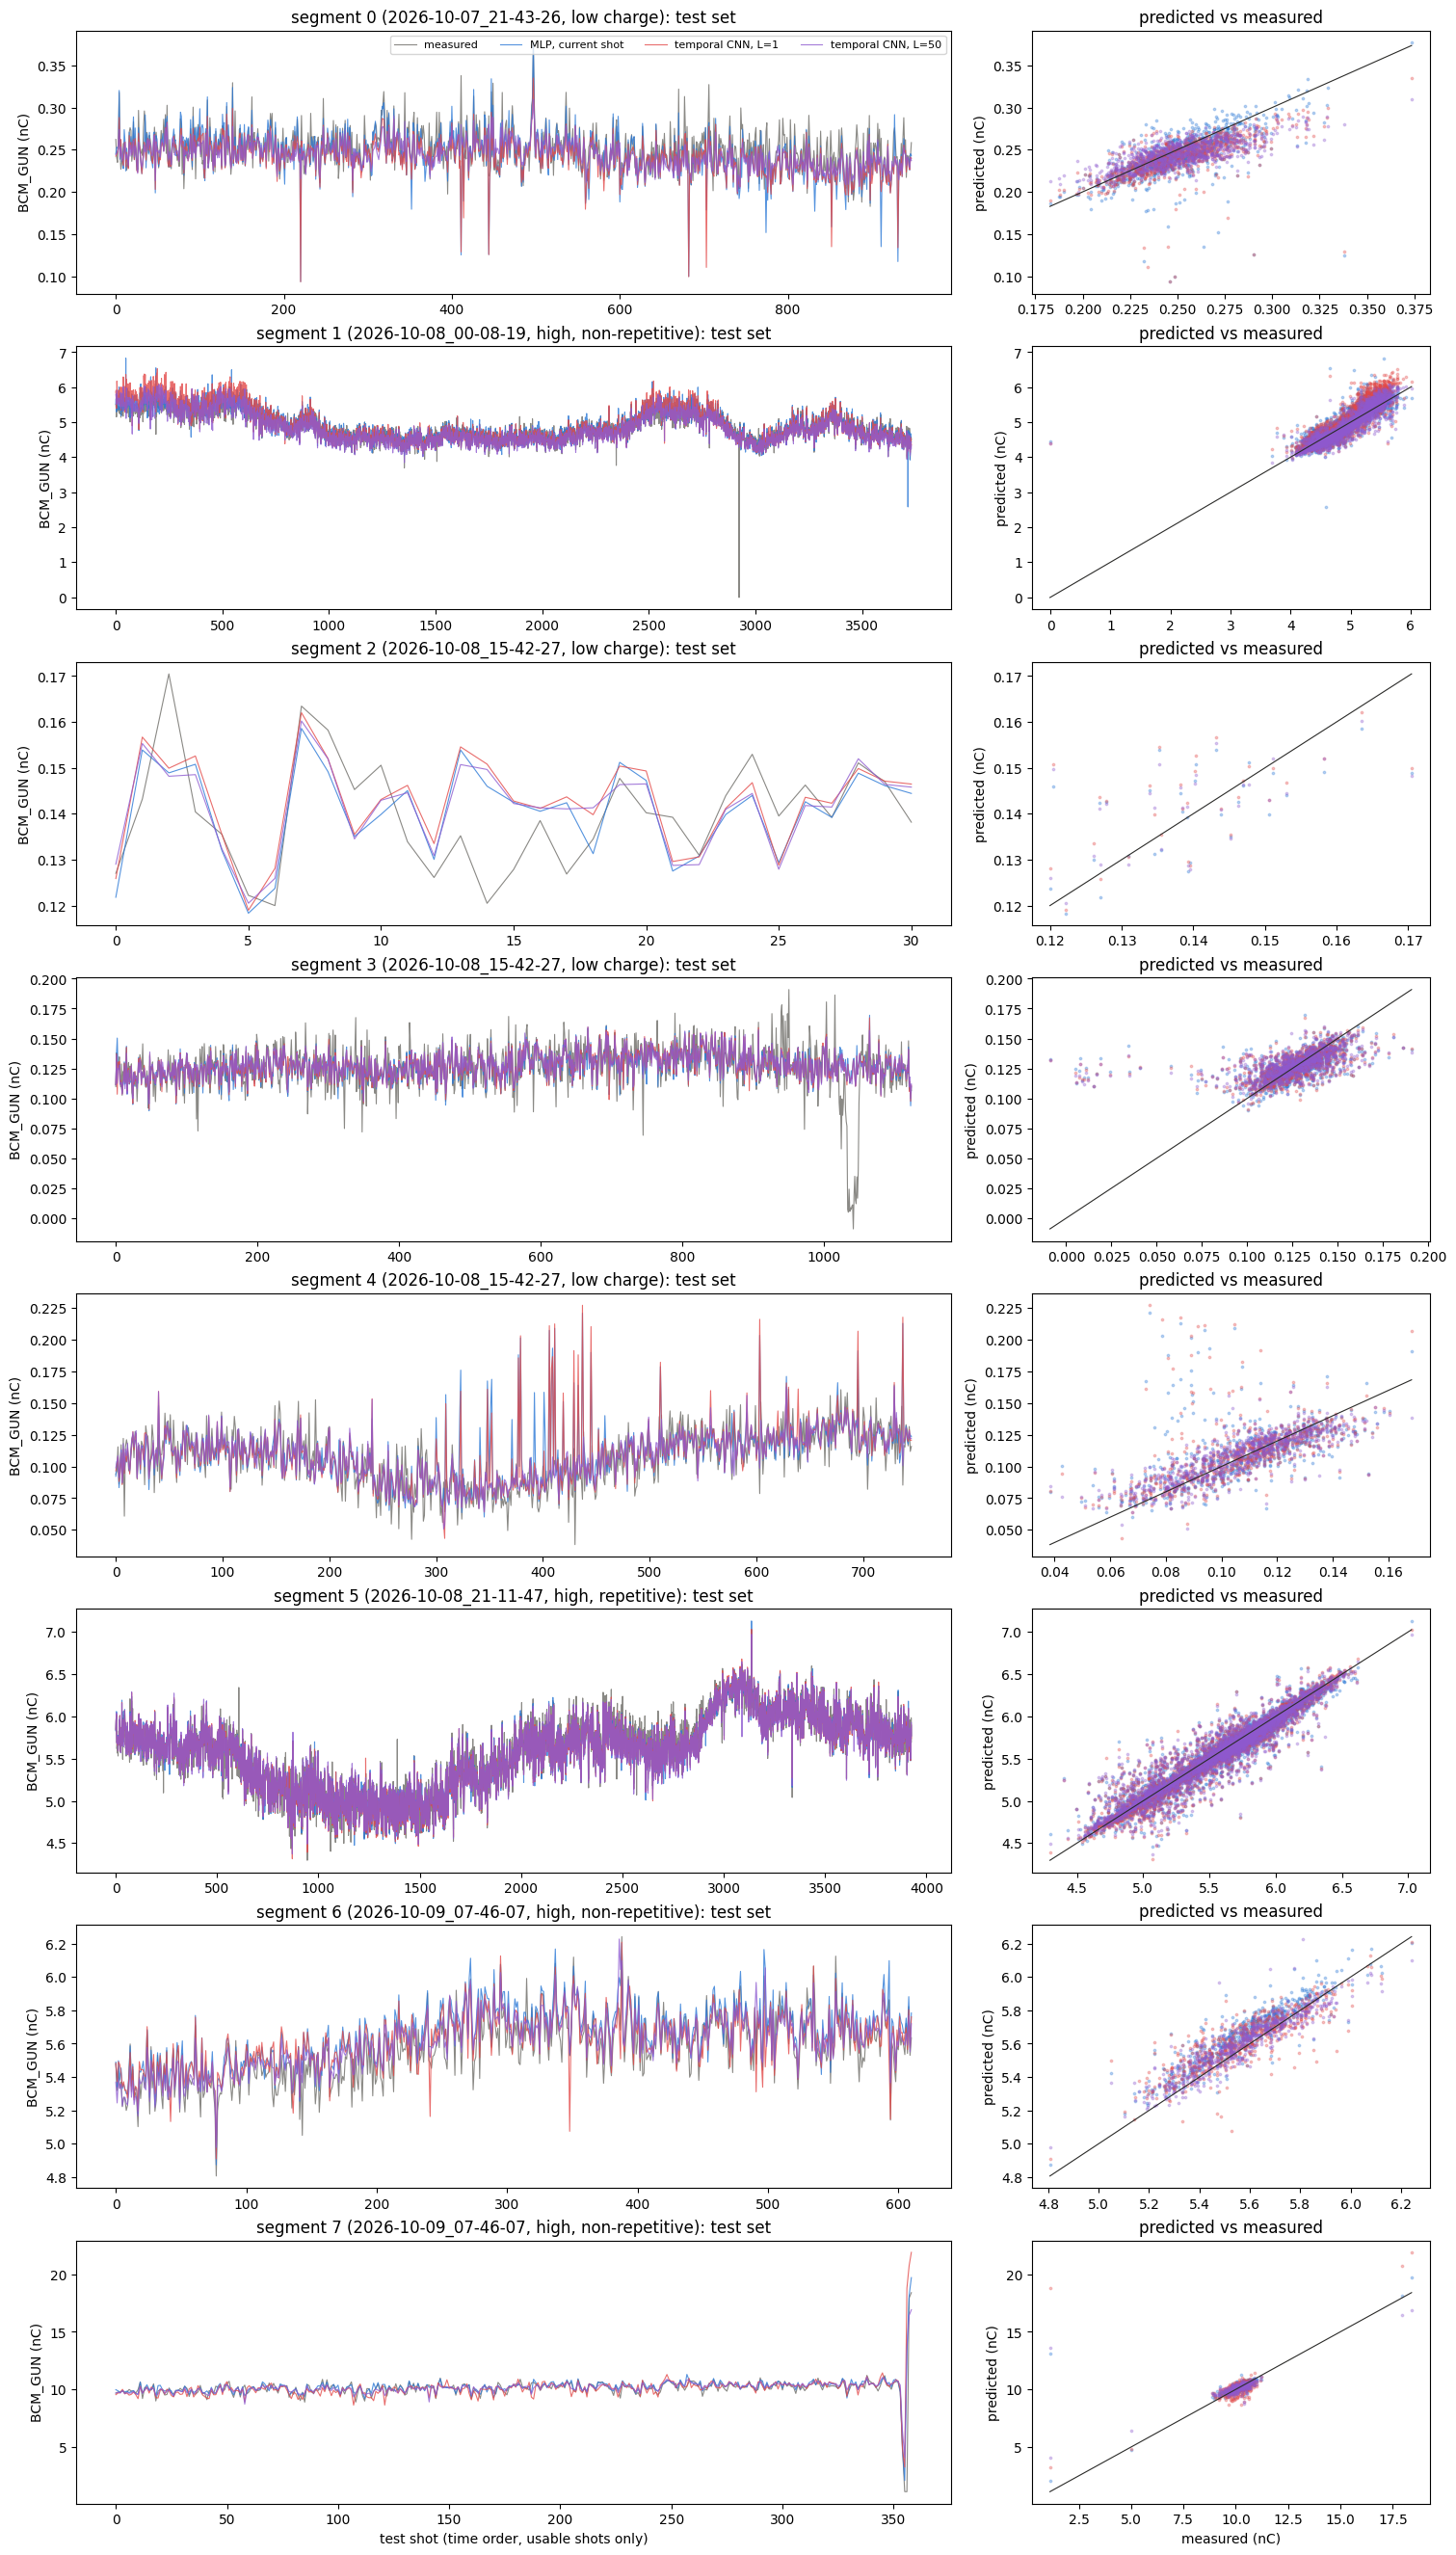

In [6]:
COLORS = {"MLP, current shot": "#2a78d6", "temporal CNN, L=1": "#e34948", f"temporal CNN, L={L}": "#8e5bd0"}
fig, axes = plt.subplots(len(curves), 2, figsize=(15, 3.3 * len(curves)), gridspec_kw={"width_ratios": [2.2, 1]},
                         layout="constrained", squeeze=False)
for (ax1, ax2), (s, (y, p)) in zip(axes, sorted(curves.items())):
    shots = np.arange(len(y))
    ax1.plot(shots, y, color="#8a8985", lw=0.8, label="measured")
    for name, color in COLORS.items():
        ax1.plot(shots, p[name], color=color, lw=0.8, alpha=0.8, label=name)
        ax2.scatter(y, p[name], s=3, color=color, alpha=0.3)
    ax2.plot([y.min(), y.max()], [y.min(), y.max()], color="#2b2b29", lw=0.8)
    run = manifest["segments"][s]["run"].removeprefix("acquisition_")
    ax1.set(ylabel="BCM_GUN (nC)", title=f"segment {s} ({run}, {REGIME_OF[s]}): test set")
    ax2.set(ylabel="predicted (nC)", title="predicted vs measured")
axes[0, 0].legend(fontsize=8, ncols=4)
axes[-1, 0].set_xlabel("test shot (time order, usable shots only)")
axes[-1, 1].set_xlabel("measured (nC)")
plt.show()